# U-Net sur ISBI 2012 (EM Segmentation Challenge)
Implémentation PyTorch de l'article [arXiv:1505.04597](https://arxiv.org/abs/1505.04597) sur son dataset principal :
30 coupes de microscopie électronique (512×512) du cordon nerveux d'une larve de drosophile.

**Ce que le notebook reproduit de l'article**
- U-Net à convolutions *valid* : entrée 572×572 → sortie 388×388
- stratégie **overlap-tile** (miroir sur les bords) pour segmenter une image entière
- **déformations élastiques** (grille 3×3, écart-type 10 px) + rotations/flips
- **carte de poids** : équilibrage des classes + bonus aux fines frontières entre cellules qui se touchent (w0=10, σ=5)
- init He


## 1. Imports et données

In [1]:
import os, glob, zipfile, urllib.request
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device :", device)
if device != "cuda":
    print("ATTENTION : GPU non active -> version réduite (BASE=16, 3 époques). "
          "Colab : Exécution > Modifier le type d'exécution > GPU (T4), puis tout relancer.")

device : cuda


In [2]:
DATA_DIR = "data"; os.makedirs(DATA_DIR, exist_ok=True)

def find(name):
    hits = [p for p in glob.glob(f"{DATA_DIR}/**/*.tif*", recursive=True) if name in os.path.basename(p).lower()]
    return hits[0] if hits else None

if not (find("train-volume") and find("train-labels")):
    url = "https://downloads.imagej.net/ISBI-2012-challenge.zip"
    try:
        zpath = os.path.join(DATA_DIR, "isbi.zip")
        urllib.request.urlretrieve(url, zpath)
        zipfile.ZipFile(zpath).extractall(DATA_DIR)
    except Exception as e:
        print("Téléchargement impossible :", e)

IMG_PATH, LAB_PATH = find("train-volume"), find("train-labels")
print(IMG_PATH, LAB_PATH)
assert IMG_PATH and LAB_PATH, "Placez train-volume.tif et train-labels.tif dans ./data"

data/train-volume.tif data/train-labels.tif


In [3]:
def read_tif(path):
    im = Image.open(path)
    frames = []
    for i in range(im.n_frames):
        im.seek(i); frames.append(np.array(im))
    return np.stack(frames)

images = read_tif(IMG_PATH).astype(np.float32) / 255.0      # (30, 512, 512)
labels = (read_tif(LAB_PATH) > 127).astype(np.uint8)         # 1 = cellule, 0 = membrane
print(images.shape, labels.shape, "| part de cellules :", labels.mean().round(3))

(30, 512, 512) (30, 512, 512) | part de cellules : 0.78


## 2. Prétraitement : carte de poids et déformations élastiques
- **Carte de poids** `w(x) = w_c(x) + w0 · exp(-(d1+d2)² / 2σ²)` où `d1`, `d2` sont les distances aux deux cellules les plus proches. Elle force le réseau à bien séparer les cellules adjacentes.
- **Déformation élastique** : déplacements aléatoires sur une grille 3×3, interpolés (cubique) à toute l'image.

In [4]:
def weight_map(lab, w0=10.0, sigma=5.0):
    freq = lab.mean()
    wc = np.where(lab == 1, 0.5 / freq, 0.5 / (1 - freq)).astype(np.float32)  # équilibrage des classes
    cells, n = ndi.label(lab)                                                    # cellules = composantes connexes
    if n < 2: return wc
    d1 = np.full(lab.shape, np.inf, np.float32); d2 = d1.copy()
    for k in range(1, n + 1):                                                    # 2 plus petites distances
        d = ndi.distance_transform_edt(cells != k).astype(np.float32)
        m = d < d1
        d2 = np.where(m, d1, np.minimum(d2, d)); d1 = np.where(m, d, d1)
    return wc + w0 * np.exp(-((d1 + d2) ** 2) / (2 * sigma ** 2))

def elastic_deform(img, lab, wm, rng, grid=3, std=10.0):
    h, w = img.shape
    disp = rng.normal(0, std, (2, grid, grid))
    disp = np.stack([ndi.zoom(d, (h / grid, w / grid), order=3) for d in disp])
    yy, xx = np.mgrid[:h, :w]
    coords = [yy + disp[0], xx + disp[1]]
    f = lambda a, o: ndi.map_coordinates(a, coords, order=o, mode="reflect")
    return f(img, 3), f(lab, 0), f(wm, 1)

cartes de poids calculées en 37s
poids normalisés : moyenne=1.00, max=4.8


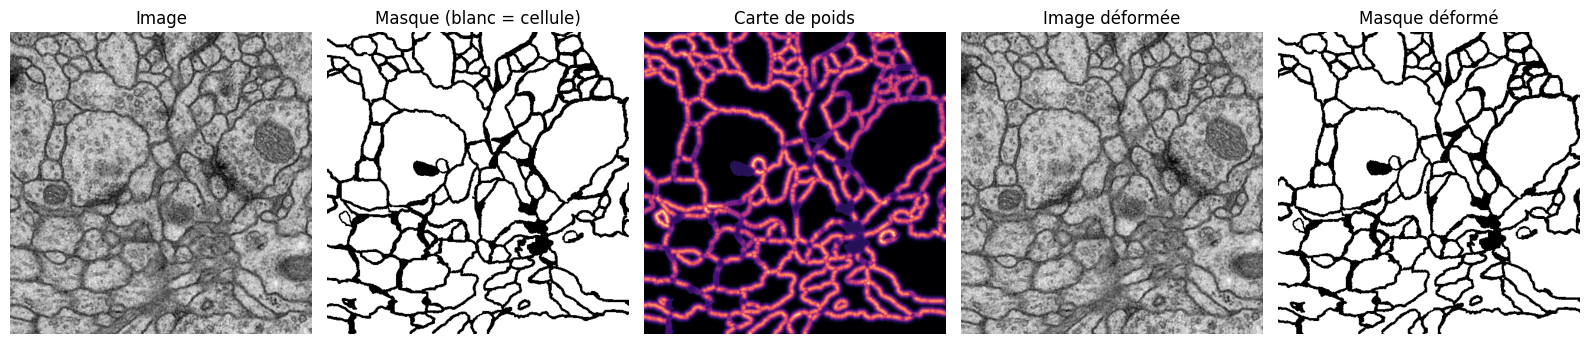

In [5]:
import time; t = time.time()
wmaps = np.stack([weight_map(l) for l in labels]).astype(np.float32)
print(f"cartes de poids calculées en {time.time()-t:.0f}s")
wmaps = wmaps / wmaps.mean()          # correction 2 : poids de moyenne 1
print(f"poids normalisés : moyenne={wmaps.mean():.2f}, max={wmaps.max():.1f}")

# Découpage : 25 coupes pour l'entraînement, 5 pour la validation
N_TRAIN = 25
tr_img, tr_lab, tr_w = images[:N_TRAIN], labels[:N_TRAIN], wmaps[:N_TRAIN]
va_img, va_lab = images[N_TRAIN:], labels[N_TRAIN:]
MEAN, STD = tr_img.mean(), tr_img.std()

# Aperçu des données, de la carte de poids et d'une déformation élastique
rng = np.random.default_rng(1)
ei, el, ew = elastic_deform(tr_img[0], tr_lab[0], tr_w[0], rng)
fig, ax = plt.subplots(1, 5, figsize=(16, 3.4))
for a, im, t_ in zip(ax, [tr_img[0], tr_lab[0], tr_w[0], ei, el],
                     ["Image", "Masque (blanc = cellule)", "Carte de poids", "Image déformée", "Masque déformé"]):
    a.imshow(im, cmap="gray" if t_ != "Carte de poids" else "magma"); a.set_title(t_); a.axis("off")
plt.tight_layout(); plt.show()

## 3. Le modèle
Convolutions 3×3 *valid* (`padding=0`) : l'image rétrécit, donc on **rogne** les skip connections avant de les concaténer. Entrée 572×572 → sortie 388×388.

In [6]:
USE_BN = True      # correction 4 : BatchNorm (mettre False pour l'architecture exacte de l'article)

def conv_block(cin, cout, use_bn):
    layers = [nn.Conv2d(cin, cout, 3, bias=not use_bn)]
    if use_bn: layers.append(nn.BatchNorm2d(cout))
    layers.append(nn.ReLU(inplace=True))
    return layers

class DoubleConv(nn.Module):
    def __init__(self, cin, cout, use_bn=True):
        super().__init__()
        self.net = nn.Sequential(*conv_block(cin, cout, use_bn), *conv_block(cout, cout, use_bn))
    def forward(self, x): return self.net(x)

def center_crop(t, target):
    th, tw = target.shape[-2:]; h, w = t.shape[-2:]
    i, j = (h - th) // 2, (w - tw) // 2
    return t[..., i:i+th, j:j+tw]

class UNet(nn.Module):
    def __init__(self, in_ch=1, n_classes=2, base=64, use_bn=USE_BN):
        super().__init__()
        chs = [base * 2**i for i in range(5)]                     # 64,128,256,512,1024
        self.downs = nn.ModuleList(); c = in_ch
        for ch in chs[:-1]:
            self.downs.append(DoubleConv(c, ch, use_bn)); c = ch
        self.pool = nn.MaxPool2d(2)
        self.bottom = DoubleConv(chs[-2], chs[-1], use_bn)
        self.ups, self.up_convs = nn.ModuleList(), nn.ModuleList()
        for ch in reversed(chs[:-1]):
            self.ups.append(nn.ConvTranspose2d(ch * 2, ch, 2, stride=2))
            self.up_convs.append(DoubleConv(ch * 2, ch, use_bn))
        self.out = nn.Conv2d(base, n_classes, 1)
        for m in self.modules():                                  # init He, comme dans l'article
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                if m.bias is not None: nn.init.zeros_(m.bias)

    def forward(self, x):
        skips = []
        for down in self.downs:
            x = down(x); skips.append(x); x = self.pool(x)
        x = self.bottom(x)
        for up, conv, skip in zip(self.ups, self.up_convs, reversed(skips)):
            x = up(x)
            x = conv(torch.cat([center_crop(skip, x), x], dim=1))
        return self.out(x)

with torch.no_grad():
    print(UNet(base=8)(torch.randn(1, 1, 572, 572)).shape)       # attendu : [1, 2, 388, 388]

torch.Size([1, 2, 388, 388])


## 4. Dataset d'entraînement (overlap-tile)
L'image (512×512) est déformée, tournée/retournée, puis **complétée par miroir de 92 px** sur chaque bord. On y découpe une tuile d'entrée 572×572 ; la cible est la zone centrale 388×388 (poids correspondants inclus).

In [7]:
IN, OUT = 572, 388
PAD = (IN - OUT) // 2        # 92
SIZE = 512

class EMTrain(Dataset):
    def __init__(self, imgs, labs, wms, n_samples):
        self.imgs, self.labs, self.wms, self.n = imgs, labs, wms, n_samples
        self.rng = np.random.default_rng(0)
    def __len__(self): return self.n
    def __getitem__(self, _):
        r = self.rng; k = r.integers(len(self.imgs))
        img, lab, wm = elastic_deform(self.imgs[k], self.labs[k], self.wms[k], r)
        rot = r.integers(4); img, lab, wm = [np.rot90(a, rot) for a in (img, lab, wm)]
        if r.random() < .5: img, lab, wm = [a[:, ::-1] for a in (img, lab, wm)]
        img = np.pad((img - MEAN) / STD, PAD, mode="reflect")
        i, j = r.integers(0, SIZE - OUT + 1, 2)
        x = img[i:i+IN, j:j+IN]; y = lab[i:i+OUT, j:j+OUT]; w = wm[i:i+OUT, j:j+OUT]
        return (torch.from_numpy(x.astype(np.float32).copy())[None],
                torch.from_numpy(y.astype(np.int64).copy()),
                torch.from_numpy(w.astype(np.float32).copy()))

# Config selon le matériel (l'architecture est identique, seule la largeur change)
if device == "cuda": BASE, EPOCHS, BATCH = 64, 30, 2     # modèle complet de l'article
else:                BASE, EPOCHS, BATCH = 16, 3, 1      # version allégée pour CPU
STEPS = 200                                              # tuiles tirées par époque
train_dl = DataLoader(EMTrain(tr_img, tr_lab, tr_w, STEPS), batch_size=BATCH)
print("BASE =", BASE, "| EPOCHS =", EPOCHS, "| BATCH =", BATCH, "| pas par époque =", len(train_dl))

BASE = 64 | EPOCHS = 30 | BATCH = 2 | pas par époque = 100


## 5. Prédiction d'une image entière (overlap-tile) et métriques
Une image 512×512 est couverte par 4 tuiles de sortie 388×388 (départs en 0 et 124), chacune calculée depuis une entrée 572×572 prise sur l'image complétée par miroir.

In [8]:
@torch.no_grad()
def predict_full(model, img):
    model.eval()
    p = np.pad((img - MEAN) / STD, PAD, mode="reflect")
    prob = np.zeros((SIZE, SIZE), np.float32)
    starts = [0, SIZE - OUT]
    for i in starts:
        for j in starts:
            x = torch.from_numpy(p[i:i+IN, j:j+IN].astype(np.float32))[None, None].to(device)
            prob[i:i+OUT, j:j+OUT] = F.softmax(model(x), 1)[0, 1].cpu().numpy()   # P(cellule)
    return prob

def metrics(prob, lab):
    pred = prob > 0.5; g = (lab == 1)
    inter = (pred & g).sum()
    dice = 2 * inter / (pred.sum() + g.sum() + 1e-9)
    iou = inter / ((pred | g).sum() + 1e-9)
    inter0 = (~pred & ~g).sum()                                   # classe membrane
    dice_mem = 2 * inter0 / ((~pred).sum() + (~g).sum() + 1e-9)
    return dict(pixel_acc=(pred == g).mean(), dice=dice, iou=iou,
                dice_mem=dice_mem, dice_mean=(dice + dice_mem) / 2,   # insensible à l'effondrement
                frac_cell=pred.mean())                                # fraction prédite « cellule »

def evaluate(model):
    ms = [metrics(predict_full(model, i), l) for i, l in zip(va_img, va_lab)]
    return {k: float(np.mean([m[k] for m in ms])) for k in ms[0]}

## 6. Entraînement
- **Perte** = entropie croisée pondérée (poids de moyenne 1, normalisée par la somme des poids) **+ perte Dice** sur les deux classes.
- **Optimiseur** : Adam, lr 1e-4 avec décroissance cosinus, écrêtage du gradient à 1, lot de 2.
- **Surveillance** : à chaque époque on affiche la fraction de pixels prédits « cellule » (vraie valeur ≈ 0.78) et le Dice des deux classes. Un Dice « cellule » de 0.89 avec une fraction ≈ 1 signifie que le réseau a **effondré** vers « tout cellule ».
- Le **meilleur modèle** (selon le Dice moyen des deux classes) est conservé et restauré à la fin.

In [9]:
LR, CLIP, LAMBDA_DICE = 1e-4, 1.0, 1.0

def dice_loss(logits, y, eps=1.0):
    """Perte Dice moyenne sur les 2 classes (robuste aux deux effondrements)."""
    p = F.softmax(logits, 1); out = 0
    for c in (0, 1):
        pc, tc = p[:, c], (y == c).float()
        inter = (pc * tc).sum(dim=(1, 2))
        out = out + (1 - (2 * inter + eps) / (pc.sum(dim=(1, 2)) + tc.sum(dim=(1, 2)) + eps)).mean()
    return out / 2

def compute_loss(out, y, w):
    ce = (F.cross_entropy(out, y, reduction="none") * w).sum() / w.sum()   # CE pondérée normalisée
    return ce + LAMBDA_DICE * dice_loss(out, y), ce

model = UNet(in_ch=1, n_classes=2, base=BASE, use_bn=USE_BN).to(device)
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * len(train_dl), eta_min=1e-6)

history, frac_hist, dicemean_hist = [], [], []
best = {"score": -1.0, "epoch": 0, "state": None}
print(f"fraction vraie de pixels « cellule » (validation) : {(va_lab == 1).mean():.3f}")

for epoch in range(EPOCHS):
    model.train(); tot, n_ok, n_skip = 0.0, 0, 0
    for x, y, w in train_dl:
        x, y, w = x.to(device), y.to(device), w.to(device)
        loss, ce = compute_loss(model(x), y, w)
        if not torch.isfinite(loss):                       # correction 3 : on saute les pas non finis
            opt.zero_grad(set_to_none=True); sched.step(); n_skip += 1; continue
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)   # correction 3 : écrêtage du gradient
        opt.step(); sched.step()
        tot += loss.item(); n_ok += 1
    m = evaluate(model)
    history.append((tot / max(n_ok, 1), m["dice"])); frac_hist.append(m["frac_cell"]); dicemean_hist.append(m["dice_mean"])
    if m["dice_mean"] > best["score"]:
        best = {"score": m["dice_mean"], "epoch": epoch + 1,
                "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
    warn = "  <-- EFFONDREMENT ?" if (m["frac_cell"] < 0.05 or m["frac_cell"] > 0.99) else ""
    skip = f" | pas ignorés={n_skip}" if n_skip else ""
    print(f"epoch {epoch+1:2d}/{EPOCHS} | loss={tot/max(n_ok,1):.4f}{skip} | val: acc={m['pixel_acc']:.3f} "
          f"dice_cell={m['dice']:.3f} dice_mem={m['dice_mem']:.3f} iou={m['iou']:.3f} | frac_cell={m['frac_cell']:.3f}{warn}")

model.load_state_dict(best["state"])                       # on restaure le meilleur modèle
print(f"\nMeilleur modèle : époque {best['epoch']} (Dice moyen des 2 classes = {best['score']:.3f})")

fraction vraie de pixels « cellule » (validation) : 0.801
epoch  1/30 | loss=0.7841 | val: acc=0.894 dice_cell=0.934 dice_mem=0.734 iou=0.876 | frac_cell=0.799
epoch  2/30 | loss=0.5555 | val: acc=0.907 dice_cell=0.943 dice_mem=0.750 iou=0.892 | frac_cell=0.825
epoch  3/30 | loss=0.5181 | val: acc=0.914 dice_cell=0.946 dice_mem=0.788 iou=0.898 | frac_cell=0.792
epoch  4/30 | loss=0.5084 | val: acc=0.917 dice_cell=0.947 dice_mem=0.805 iou=0.900 | frac_cell=0.773
epoch  5/30 | loss=0.4996 | val: acc=0.918 dice_cell=0.949 dice_mem=0.800 iou=0.902 | frac_cell=0.790
epoch  6/30 | loss=0.4872 | val: acc=0.915 dice_cell=0.946 dice_mem=0.798 iou=0.898 | frac_cell=0.775
epoch  7/30 | loss=0.4785 | val: acc=0.923 dice_cell=0.951 dice_mem=0.816 iou=0.907 | frac_cell=0.777
epoch  8/30 | loss=0.4770 | val: acc=0.921 dice_cell=0.950 dice_mem=0.810 iou=0.904 | frac_cell=0.779
epoch  9/30 | loss=0.4710 | val: acc=0.921 dice_cell=0.950 dice_mem=0.806 iou=0.906 | frac_cell=0.789
epoch 10/30 | loss=0.466

## 7. Les Résultats

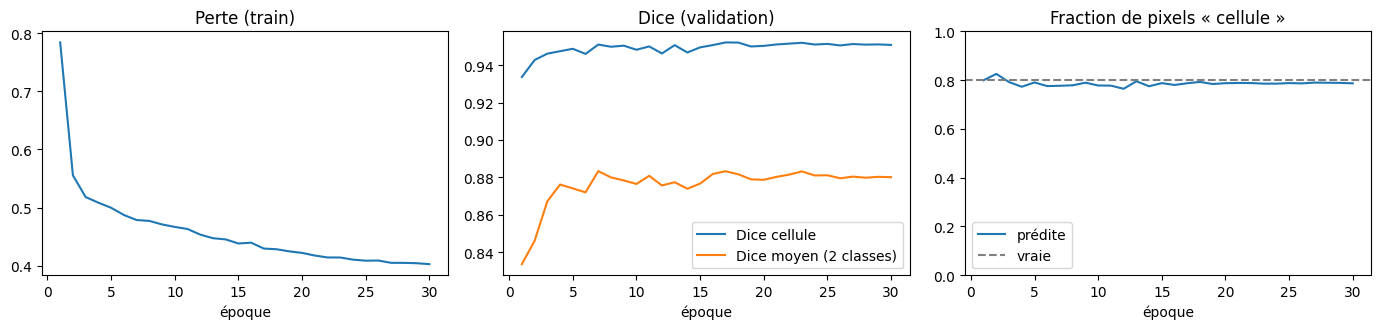

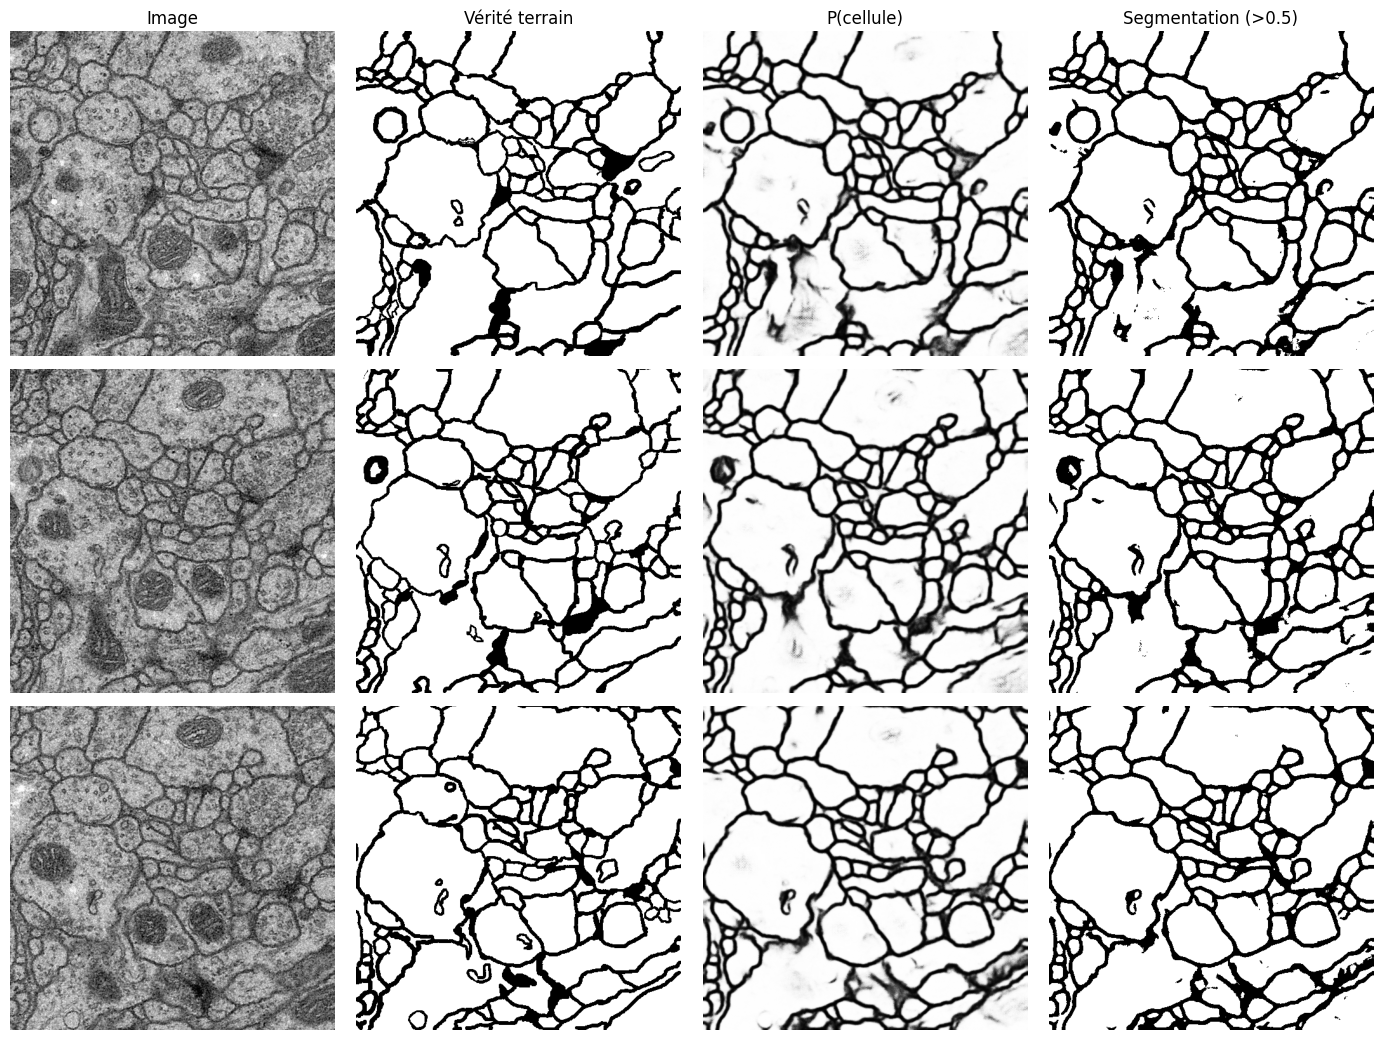

{'pixel_acc': 0.9225906372070313, 'dice': 0.9509712189062297, 'iou': 0.9065670550792948, 'dice_mem': 0.8157411824468174, 'dice_mean': 0.8833562006765237, 'frac_cell': 0.7768318176269531}


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
ep = range(1, len(history) + 1)
ax[0].plot(ep, [h[0] for h in history]); ax[0].set_title("Perte (train)"); ax[0].set_xlabel("époque")
ax[1].plot(ep, [h[1] for h in history], label="Dice cellule"); ax[1].plot(ep, dicemean_hist, label="Dice moyen (2 classes)")
ax[1].set_title("Dice (validation)"); ax[1].set_xlabel("époque"); ax[1].legend()
ax[2].plot(ep, frac_hist, label="prédite"); ax[2].axhline((va_lab == 1).mean(), color="gray", ls="--", label="vraie")
ax[2].set_ylim(0, 1); ax[2].set_title("Fraction de pixels « cellule »"); ax[2].set_xlabel("époque"); ax[2].legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(3, 4, figsize=(14, 10.5))
for c in range(3):
    prob = predict_full(model, va_img[c])
    ax[c,0].imshow(va_img[c], cmap="gray"); ax[c,1].imshow(va_lab[c], cmap="gray")
    ax[c,2].imshow(prob, cmap="gray", vmin=0, vmax=1); ax[c,3].imshow(prob > 0.5, cmap="gray")
    for a in ax[c]: a.axis("off")
for a, t in zip(ax[0], ["Image", "Vérité terrain", "P(cellule)", "Segmentation (>0.5)"]): a.set_title(t)
plt.tight_layout(); plt.show()
print(evaluate(model))

## 8. Évaluation complémentaire
- **TTA** (*test-time augmentation*) : moyenne des prédictions sur les 8 transformations (4 rotations × flip). Non utilisé dans l'article, mais gratuit en précision.
- **Erreurs « façon ISBI »** : *pixel error* (1 − exactitude) et *adapted Rand error* calculée sur les cellules (composantes connexes) avec le meilleur seuil. C'est une **approximation** : le classement officiel utilise l'outil du challenge sur le jeu de test, dont les étiquettes ne sont pas publiques ; ces valeurs ne sont donc pas directement comparables au tableau de l'article.

In [11]:
from skimage.measure import label as cc_label
from skimage.metrics import adapted_rand_error

@torch.no_grad()
def predict_tta(model, img):
    acc = np.zeros(img.shape, np.float32)
    for k in range(4):
        for flip in (False, True):
            a = np.rot90(img, k)
            if flip: a = a[:, ::-1]
            p = predict_full(model, np.ascontiguousarray(a))
            if flip: p = p[:, ::-1]
            acc += np.rot90(p, -k)
    return acc / 8

def isbi_like(probs, labs, thresholds=(0.3, 0.4, 0.5, 0.6, 0.7)):
    best = None
    for t in thresholds:
        errs = []
        for p, l in zip(probs, labs):
            gt = cc_label(l == 1, connectivity=1, background=0)
            pr = cc_label(p > t, connectivity=1, background=0)
            errs.append(adapted_rand_error(gt, pr)[0])
        e = float(np.mean(errs))
        if best is None or e < best[1]: best = (t, e)
    pix = float(np.mean([((p > 0.5) != (l == 1)).mean() for p, l in zip(probs, labs)]))
    return dict(pixel_error=pix, rand_error=best[1], best_threshold=best[0])

p_plain = [predict_full(model, i) for i in va_img]
p_tta   = [predict_tta(model, i)  for i in va_img]
print("sans TTA :", isbi_like(p_plain, va_lab), "| Dice moyen =", np.mean([metrics(p, l)["dice"] for p, l in zip(p_plain, va_lab)]).round(3))
print("avec TTA :", isbi_like(p_tta,   va_lab), "| Dice moyen =", np.mean([metrics(p, l)["dice"] for p, l in zip(p_tta,   va_lab)]).round(3))

sans TTA : {'pixel_error': 0.07740936279296876, 'rand_error': 0.09106078428753854, 'best_threshold': 0.3} | Dice moyen = 0.951
avec TTA : {'pixel_error': 0.0777862548828125, 'rand_error': 0.07065176590187339, 'best_threshold': 0.4} | Dice moyen = 0.951
